In [1]:
import numpy as np
import matplotlib.pyplot as plt


In [2]:
# Data Generation
c = 1e-3

def target_function(x, y, c=c):
    # f(x, y) = exp(-(x^2 + y^2) / 8) * cos(sqrt(x^2 + y^2) + c)
    r2 = x**2 + y**2
    return np.exp(-r2/8) * np.cos(np.sqrt(r2) + c)


def generate_data(start, end, step=0.2):

    v = np.round(np.arange(start, end+step/2, step), 10)
    xx, yy = np.meshgrid(v,v)
    X = np.column_stack([xx.ravel(), yy.ravel()])
    y = target_function(X[:,0], X[:,1]).reshape(-1,1)
    return X,y,v


X_train, y_train, grid_train = generate_data(-2, 2)
X_test, y_test, grid_test = generate_data(-1.9, 1.9)

print("Train:", X_train.shape, y_train.shape, "| grid:", grid_train[:3], "...", grid_train[-1])
print("Test: ", X_test.shape, y_test.shape, "| grid:", grid_test[:3], "...", grid_test[-1])

Train: (441, 2) (441, 1) | grid: [-2.  -1.8 -1.6] ... 2.0
Test:  (400, 2) (400, 1) | grid: [-1.9 -1.7 -1.5] ... 1.9


Data Generation:

x and y both go from -2 to 2 in steps of 0.2, which gives 21 values each. np.meshgrid pairs every x with every y, so the network sees the whole square and not just one line through it. This gives 441 training points, stored as a 441 x 2 input matrix, with f(x, y) as the target.

The test set uses the same step from -1.9 to 1.9, which gives 400 points. These sit exactly between the training points, so the network is never tested on a point it trained on.

np.arange with a step of 0.2 gives values like 0.20000000000000018 because of floating point error, so the values are rounded to 10 decimal places.

Final training MSE: 1.077e-03


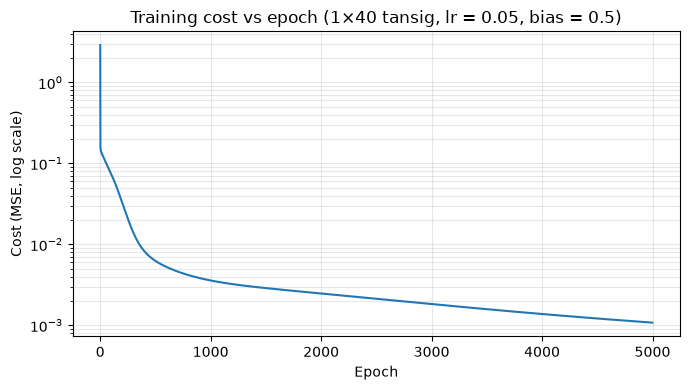

In [3]:
ACTIVATIONS = {
    "tansig": (np.tanh,                            lambda a: 1 - a**2),
    "logsig": (lambda z: 1 / (1 + np.exp(-z)),     lambda a: a * (1 - a)),
    "relu":   (lambda z: np.maximum(0, z),         lambda a: (a > 0).astype(float)),
}

def forward(model, X):

    g = ACTIVATIONS[model["activation"]][0]
    A = [X]
    n_layers = len(model["W"])
    for l in range(n_layers):
        z = A[-1] @ model["W"][l] + model["b"][l]
        A.append(z if l == n_layers - 1 else g(z))   # linear output layer
    return A

# Model Training
def train(X_train, y_train,
                epochs=5000,
                lr=0.05,
                hidden_layers=[40],
                activation="tansig",
                bias_init=0.5, 
                seed = 0):
    """
    Parameters:
        X_train, y_train : training data
        epochs : number of iterations
        lr : learning rate
        hidden_layers : list of hidden layer sizes, e.g. [40] or [64,32]
        activation : activation function name ('tansig', 'logsig', 'relu', etc.)
        bias_init : initial bias value (float)

    Returns:
        model_params, losses
    """
    rng = np.random.default_rng(seed)
    sizes = [X_train.shape[1]] + list(hidden_layers) + [y_train.shape[1]]

    # initialize weights (Xavier uniform) and biases (constant bias_init)
    W = [rng.uniform(-1, 1, (n_in, n_out)) * np.sqrt(6 / (n_in + n_out))
        for n_in, n_out in zip(sizes[:-1], sizes[1:])]
    b = [np.full((1, n_out), float(bias_init)) for n_out in sizes[1:]]
    model = {"W": W, "b": b, "activation": activation}

    # select activation derivative
    g_prime = ACTIVATIONS[activation][1]

    losses = []
    N = len(X_train)
    for epoch in range(epochs):
        # forward pass
        A = forward(model, X_train)
        y_hat = A[-1]

        loss = np.mean((y_hat - y_train) ** 2)
        if not np.isfinite(loss):
            print(f"  diverged at epoch {epoch} (lr={lr}, activation={activation})")
            break
        losses.append(loss)

        # backward pass
        delta = 2 * (y_hat - y_train) / N
        for l in range(len(W) - 1, -1, -1):
            grad_W = A[l].T @ delta
            grad_b = delta.sum(axis=0, keepdims=True)
            if l > 0:
                delta = (delta @ W[l].T) * g_prime(A[l])   # uses W[l] before it is updated
            W[l] -= lr * grad_W
            b[l] -= lr * grad_b

    return model, np.array(losses)
    
# call train and capture losses
model, losses = train(X_train, y_train, epochs=5000, lr=0.05,
                        hidden_layers=[40], activation="tansig", bias_init=0.5)
print(f"Final training MSE: {losses[-1]:.3e}")

# plot cost vs epoch
plt.figure(figsize=(7, 4))
plt.semilogy(losses)
plt.xlabel("Epoch")
plt.ylabel("Cost (MSE, log scale)")
plt.title("Training cost vs epoch (1×40 tansig, lr = 0.05, bias = 0.5)")
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()



Model Training:

Network: 2 inputs, one hidden layer of 40 tansig neurons, and 1 linear output neuron. The output is linear because this is regression, so the output needs to be able to take any value.

Settings: learning rate 0.05, 5000 epochs, and every bias starts at 0.5. The weights start small and random using Xavier initialisation, which scales them by layer size so the signal does not blow up or die out as it goes through the network.

Cost: mean squared error. Each epoch runs all 441 points forward, backpropagates the error layer by layer to get the gradient for every weight and bias, and takes one gradient descent step. hidden_layers is a list, so the same code handles [40], [40, 40] and so on in part d.

What the cost curve shows:

The cost drops from about 3 to about 0.15 in the first few epochs, as the network fixes its overall offset. It then falls steeply until about epoch 500 while it learns the shape of the function. After that it keeps falling slowly and ends at a training MSE of 1.08e-3. It never goes back up, so the learning rate is a sensible size. It is still falling at epoch 5000, so more epochs would help a little.

Train MSE: 1.077e-03   max |error|: 0.150
Test  MSE: 7.437e-04   max |error|: 0.107


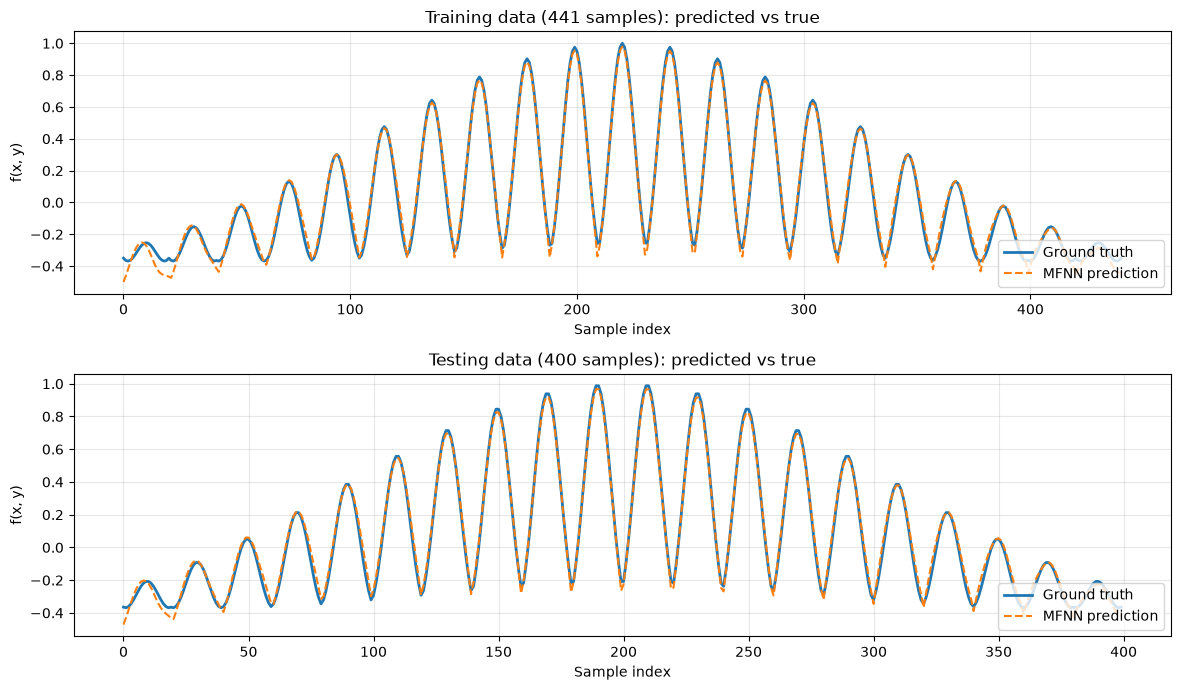

In [4]:
# Model Testing
def predict(model, X_test):
    # forward pass only
    return forward(model, X_test)[-1]

def mse(a, b):
    return np.mean((a - b) ** 2)

# run predictions on train & test
pred_train = predict(model, X_train)
pred_test = predict(model, X_test)
print(f"Train MSE: {mse(pred_train, y_train):.3e}   max |error|: {np.max(np.abs(pred_train - y_train)):.3f}")
print(f"Test  MSE: {mse(pred_test, y_test):.3e}   max |error|: {np.max(np.abs(pred_test - y_test)):.3f}")

# plot predicted vs ground truth: every sample, train and test kept separate
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, y_true, y_pred, name in [(axes[0], y_train, pred_train, "Training"),(axes[1], y_test, pred_test, "Testing")]:
    ax.plot(y_true, label="Ground truth", linewidth=2)
    ax.plot(y_pred, "--", label="MFNN prediction", linewidth=1.5)
    ax.set_title(f"{name} data ({len(y_true)} samples): predicted vs true")
    ax.set_xlabel("Sample index")
    ax.set_ylabel("f(x, y)")
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Model Testing:

Train: MSE 1.08e-3, largest single error 0.150.

Test: MSE 7.44e-4, largest single error 0.107.

f ranges from about -0.37 to 1, and an MSE of 1e-3 means a typical prediction is off by about 0.03. The train and test errors are close, so the network learned the function and did not just memorise the training points.

The plot shows every sample in order. The wave pattern comes from how the grid was flattened: each wave is one sweep across x for a fixed y, and the waves are tallest in the middle because the peak of f is at the origin. The prediction follows the truth almost everywhere. The visible misses are at the very start (a corner of the square) and at some of the troughs, where the network dips slightly too low.

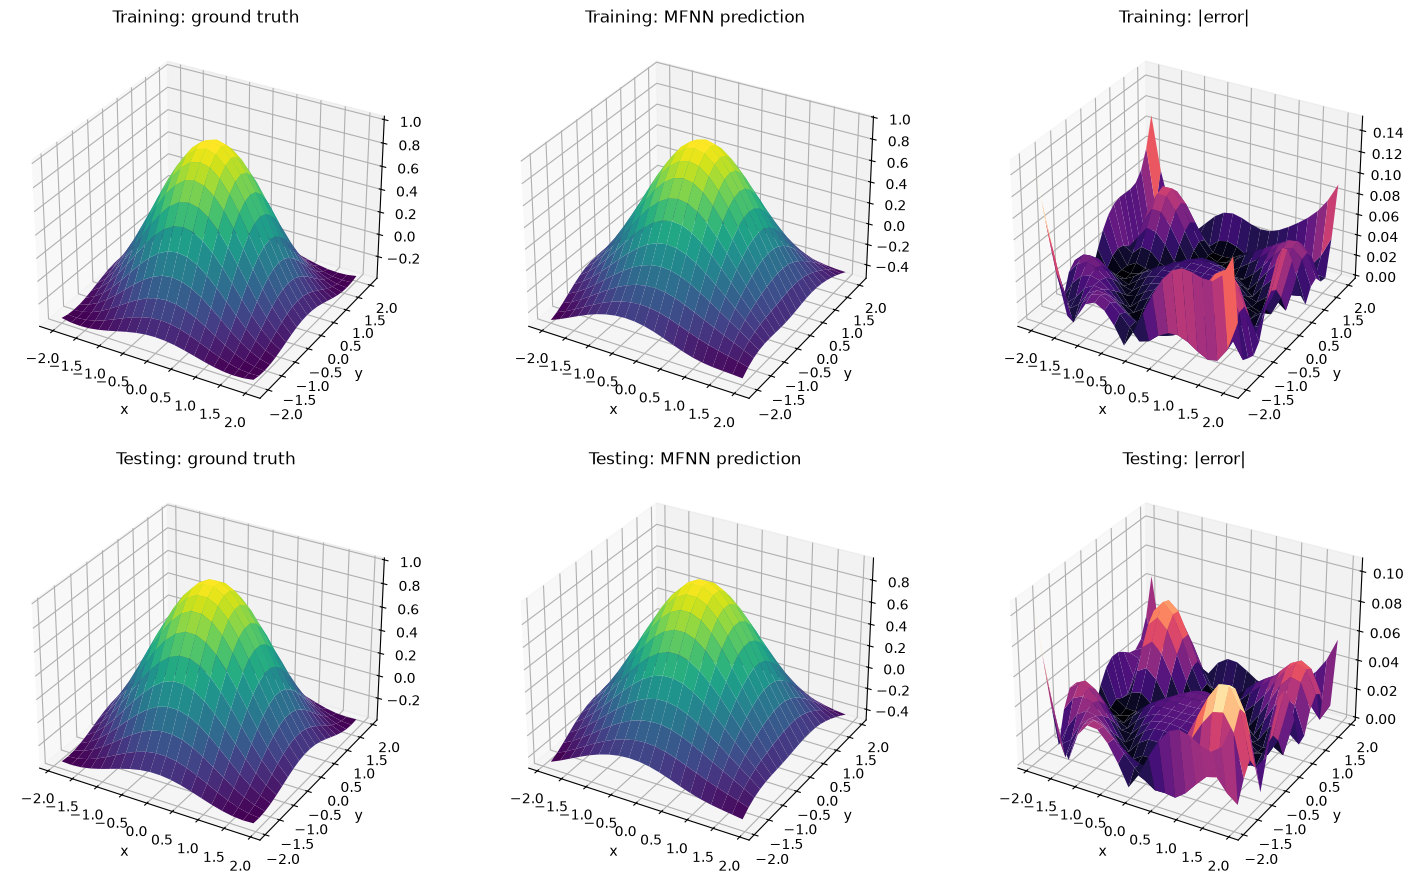

In [5]:
def as_grid(values, grid):
    return values.reshape(len(grid), len(grid))

fig = plt.figure(figsize=(15, 9))
panels = [
    (grid_train, y_train, "Training: ground truth"),
    (grid_train, pred_train, "Training: MFNN prediction"),
    (grid_train, np.abs(pred_train - y_train), "Training: |error|"),
    (grid_test, y_test, "Testing: ground truth"),
    (grid_test, pred_test, "Testing: MFNN prediction"),
    (grid_test, np.abs(pred_test - y_test), "Testing: |error|"),
]
for i, (grid, values, title) in enumerate(panels):
    ax = fig.add_subplot(2, 3, i + 1, projection="3d")
    xx, yy = np.meshgrid(grid, grid)
    ax.plot_surface(xx, yy, as_grid(values, grid), cmap="viridis" if "error" not in title else "magma")
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
plt.tight_layout()
plt.show()

The predicted surface is almost the same as the true one: the same central bump and the same fall off towards the edges. The error plots show that the network struggles most at the corners. That is where the function curves back up and where there are the fewest neighbouring training points to pin the fit down.

This is also why the test error is lower than the training error. The test grid stops at ±1.9, so it never reaches the corners where the largest errors are.

  diverged at epoch 128 (lr=0.3, activation=tansig)


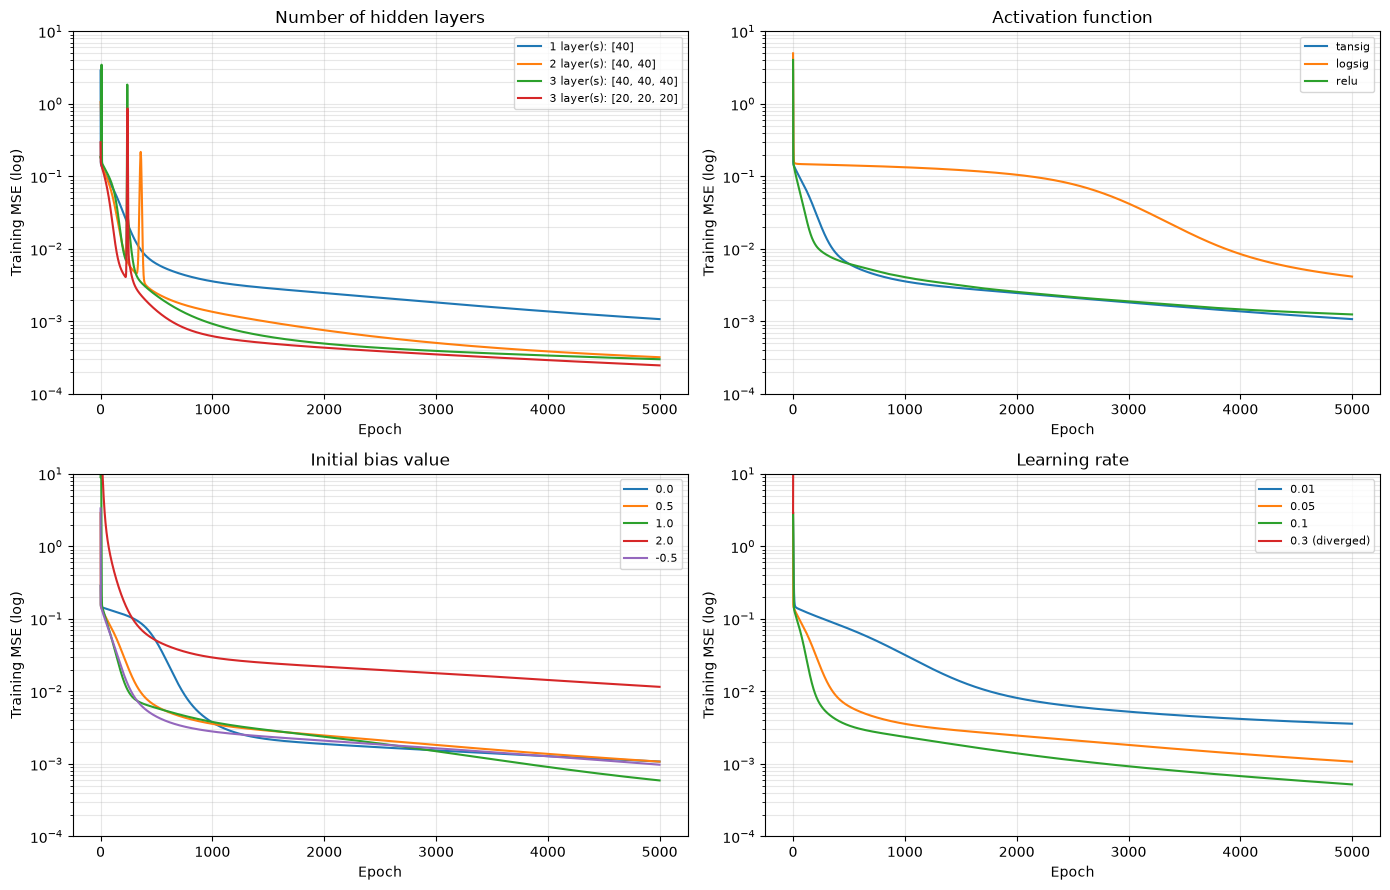


=== Number of hidden layers ===
           hidden_layers  train MSE  test MSE  diverged
        1 layer(s): [40]   1.08e-03  7.44e-04     False
    2 layer(s): [40, 40]   3.21e-04  2.32e-04     False
3 layer(s): [40, 40, 40]   3.01e-04  2.10e-04     False
3 layer(s): [20, 20, 20]   2.48e-04  1.58e-04     False

=== Activation function ===
activation  train MSE  test MSE  diverged
    tansig   1.08e-03  7.44e-04     False
    logsig   4.16e-03  3.43e-03     False
      relu   1.25e-03  9.26e-04     False

=== Initial bias value ===
bias_init  train MSE  test MSE  diverged
      0.0   1.08e-03  7.02e-04     False
      0.5   1.08e-03  7.44e-04     False
      1.0   5.93e-04  4.17e-04     False
      2.0   1.16e-02  1.20e-02     False
     -0.5   9.77e-04  6.76e-04     False

=== Learning rate ===
  lr  train MSE  test MSE  diverged
0.01   3.59e-03  2.84e-03     False
0.05   1.08e-03  7.44e-04     False
 0.1   5.22e-04  3.40e-04     False
 0.3        NaN       NaN      True


In [6]:
# Exploring hyperparameters
# Suggested learning rates to compare: 0.01, 0.1, 0.3
# Also compare: number of hidden layers, activation function (tansig vs logsig vs relu), initial bias value

import pandas as pd

BASELINE = dict(epochs=5000, lr=0.05, hidden_layers=[40], activation="tansig", bias_init=0.5)

def run_experiment(param, values, label=str):
    rows, curves = [], {}
    for v in values:
        cfg = {**BASELINE, param: v}
        with np.errstate(over="ignore", invalid="ignore"):
            m, l = train(X_train, y_train, **cfg)
        diverged = len(l) < cfg["epochs"]
        rows.append({param: label(v),
                     "train MSE": np.nan if diverged else mse(predict(m, X_train), y_train),
                     "test MSE": np.nan if diverged else mse(predict(m, X_test), y_test),
                     "diverged": diverged})
        curves[label(v)] = l
    return pd.DataFrame(rows), curves

experiments = {
    "Number of hidden layers": ("hidden_layers", [[40], [40, 40], [40, 40, 40], [20, 20, 20]],
                                lambda v: f"{len(v)} layer(s): {v}"),
    "Activation function":     ("activation", ["tansig", "logsig", "relu"], str),
    "Initial bias value":      ("bias_init", [0.0, 0.5, 1.0, 2.0, -0.5], str),
    "Learning rate":           ("lr", [0.01, 0.05, 0.1, 0.3], str),
}

all_results = {}
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (title, (param, values, label)) in zip(axes.ravel(), experiments.items()):
    table, curves = run_experiment(param, values, label)
    all_results[title] = table
    for name, l in curves.items():
        ax.semilogy(np.minimum(l, 1e3), label=name + (" (diverged)" if len(l) < BASELINE["epochs"] else ""))
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Training MSE (log)")
    ax.set_ylim(1e-4, 10)   # fixed range so a diverging run doesn't blow up the axis
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for title, table in all_results.items():
    print(f"\n=== {title} ===")
    print(table.to_string(index=False, float_format=lambda x: f"{x:.2e}"))

Fine-Tuning:

Each experiment changes one setting and keeps the rest at the baseline (1 x 40, tansig, lr 0.05, bias 0.5, 5000 epochs). All runs use the same random seed, so differences smaller than about 1.5x could just be chance.

Number of layers:

1 layer of 40: test MSE 7.44e-4 (161 weights and biases)

2 layers of 40: 2.32e-4 (1,801)

3 layers of 40: 2.10e-4 (3,441)

3 layers of 20: 1.58e-4 (921)

Depth made the biggest difference. A second layer cut the test error by about 3x, because each layer can combine the features learned by the one before it. The gains shrink quickly, and three layers of 40 is barely better than two. Three layers of 20 did best while using about half the parameters of two layers of 40, so depth matters more than width here. The deeper networks were less stable early on, with sharp loss spikes in the first few hundred epochs, and they are slower per epoch.

Activation function:

tansig: 7.44e-4

relu: 9.26e-4

logsig: 3.43e-3

tansig is best and relu is close. relu builds its output from straight line pieces, so it fits the smooth peak slightly worse. logsig is about 4 to 5x worse. Its loss sat on a plateau around 0.15 for about 2,500 epochs before it started improving. The sigmoid's slope is at most 0.25 (tanh's is 1), so the gradients are smaller and learning is slower. Its output is also always positive instead of centred on zero, which makes the weight updates less efficient.

Biases:

-0.5: 6.76e-4

0.0: 7.02e-4

0.5: 7.44e-4

1.0: 4.17e-4

2.0: 1.20e-2

Between -0.5 and 1.0 the starting bias barely matters, because backpropagation quickly moves the biases to where they need to be. The differences between those four are small enough to be chance. A bias of 2.0 is about 16x worse. Every hidden neuron starts with a large input, which pushes tanh into its flat region where the slope is close to zero (tanh'(2) ≈ 0.07). The gradients are tiny, so those neurons barely learn. This is called saturation, and it is the same reason logsig was slow.

Learning rate:

0.01: 2.84e-3

0.05: 7.44e-4

0.1: 3.40e-4

0.3: diverged at epoch 128

0.01 takes steps that are too small, and its curve is still falling at epoch 5000. 0.1 is best, about 2x better than 0.05, since it moves faster without becoming unstable. 0.3 blows up. Each step jumps over the minimum and lands further away on the other side. Once each step makes the error bigger, it compounds every epoch until the weights overflow to NaN. With a simple cost like w², the update is w ← w(1 − 2·lr), so w shrinks towards the minimum when |1 − 2·lr| < 1 and grows every step otherwise. The network behaves the same way along its steepest direction. Our cost is MSE without the ½ in front, so our gradients are twice as large, and lr 0.3 here behaves like 0.6 would with ½·MSE.

Summary:

Depth and learning rate had the biggest effect. The activation function had a moderate effect, mainly that logsig was slow. The starting bias hardly mattered unless it was large enough to saturate the neurons. The best single change was adding layers (3 x 20 got the test MSE down to 1.58e-4), and raising the learning rate to 0.1 was a close second with no extra compute.